# LAB 09 — Bias, Variance and Imbalanced Data
## Overfitting, ROC/AUC, Resampling, SMOTE and Noisy Data on Real Medical Data

## Student Information
- **Name:**Amara Latif
- **Student ID:** 023-24-0012
- **Section:** B
- **GitHub:**
- **Kaggle:**
- **Dataset:** Stroke Prediction Dataset (Kaggle)
- **Dataset Source:** https://www.kaggle.com/datasets/fedesoriano/stroke-prediction-dataset

### Before You Start
- You already know the models, scaling, splitting and cross-validation from Labs 3-8. This lab does not re-teach them.
- Every task ends with a question about **your own results**. A table or plot without a written interpretation earns no marks.
- Use `SEED = 42` everywhere. **Golden rule:** anything that learns from data (scaler, imputer, resampler, threshold) is learned from the **training data only**.
- Install once if needed: `pip install imbalanced-learn`


---

## Part 0 — Setup and the Data
A hospital wants to flag patients at risk of stroke from routine information. Target: `stroke` (1 = had a stroke, 0 = did not).

**What to do:**
1. Import everything you need (including `imblearn`) and set `SEED = 42`.
2. Load the CSV. Report the shape, the columns with missing values, the value counts of `gender`, and the number of patients with `stroke = 1` and `stroke = 0` (count and %).
3. Clean: remove the identifier column; remove any `gender` category with too few rows to learn or test; apply categorical encoding (`pd.get_dummies`) to the text columns.
4. Split 80/20 with `stratify=y`, `random_state=SEED`. Fill missing numeric values with a median learned from the **train** set only. Make a scaled copy (`StandardScaler` fitted on train) for Logistic Regression.
5. Report the number of stroke cases in the train and in the test set.

In [5]:
# YOUR CODE HERE
!pip install -q imbalanced-learn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score , 
                            precision_score, 
                            recall_score, 
                            f1_score,
                            roc_auc_score , 
                            average_precision_score,confusion_matrix)
from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler
SEED = 42
print("All libraries imported successfully!")

All libraries imported successfully!



[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [9]:
# YOUR CODE HERE
df = pd.read_csv("healthcare-dataset-stroke-data.csv")
print("Dataset Shape:")
print(df.shape)
print("\nDataset Information:")
df.info()
print("\nMissing Values:")
print(df.isnull().sum())
print("\nGender Counts:")
print(df["gender"].value_counts())
print("\nStroke Counts:")
print(df["stroke"].value_counts())
print("\nStroke Percentages:")
print(df["stroke"].value_counts(normalize=True) * 100)

df = df.drop(columns=["id"])

gender_counts = df["gender"].value_counts()
rare_gender = gender_counts[gender_counts < 2].index
df = df[~df["gender"].isin(rare_gender)]
print(df["gender"].value_counts())

X = df.drop(columns=["stroke"])
y = df["stroke"]

X = pd.get_dummies(X, drop_first=True, dtype=int)
print(X.head())


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20,random_state=SEED,stratify=y)
numeric_cols = X_train.select_dtypes(include=np.number).columns

imputer = SimpleImputer(strategy="median")

X_train[numeric_cols] = imputer.fit_transform(
    X_train[numeric_cols]
)

X_test[numeric_cols] = imputer.transform(
    X_test[numeric_cols]
)

scaler = StandardScaler()

X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_test_scaled = pd.DataFrame(
    scaler.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

print("Training Set Stroke Counts:")
print(y_train.value_counts())

print("\nTesting Set Stroke Counts:")
print(y_test.value_counts())

print("\nTraining Stroke Patients:")
print((y_train == 1).sum())

print("\nTesting Stroke Patients:")
print((y_test == 1).sum())


Dataset Shape:
(5110, 12)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   str    
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   str    
 6   work_type          5110 non-null   str    
 7   Residence_type     5110 non-null   str    
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   str    
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), str(5)
memory usage: 634.7 KB

Missing Values:
id                     0
gender                 0
age                    0
hypertension           0
heart_d

**Question 0.1:** In 2–3 lines: how imbalanced is the data? Why did we use `stratify=y`, and what could go wrong with only a few stroke cases in the test set?

**Your answer:**
The dataset is highly imbalanced because only 249 patients (approximately 4.87%) had a stroke, while 4,861 patients (approximately 95.13%) did not have a stroke. We used stratify=y to maintain the same class distribution in both training and testing datasets. If the test set contains very few stroke cases, the evaluation results may become unreliable because even a few incorrect predictions can significantly affect recall and precision.


---

## Part 1 — The Accuracy Trap
**Objective:** show that a model can have excellent accuracy and still be useless.
1. Build a baseline that always predicts the majority class (`DummyClassifier(strategy='most_frequent')`). Report accuracy.
2. Train a default Logistic Regression on the scaled training data. Report Accuracy, Precision, Recall, F1, ROC AUC and PR AUC (average precision) on the test set, and print the confusion matrix.
3. Write a helper function that takes a model and train/test data and returns these six metrics (you will reuse it all lab).

Baseline Accuracy: 0.9510763209393346
Accuracy     0.952055
Precision    1.000000
Recall       0.020000
F1           0.039216
ROC AUC      0.839424
PR AUC       0.269219
dtype: float64
[[972   0]
 [ 49   1]]


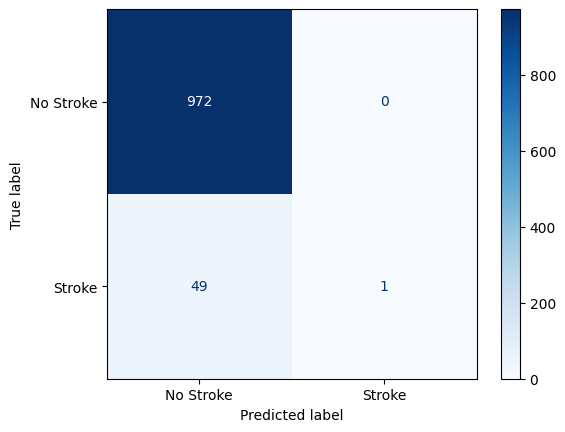

In [ ]:
# YOUR CODE HERE
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score

# Create baseline model
dummy_model = DummyClassifier(strategy="most_frequent")
# Train the model
dummy_model.fit(X_train, y_train)
# Predict test data
dummy_predictions = dummy_model.predict(X_test)
# Calculate accuracy
dummy_accuracy = accuracy_score(y_test, dummy_predictions)
print("Baseline Accuracy:", dummy_accuracy)


Accuracy     0.952055
Precision    1.000000
Recall       0.020000
F1           0.039216
ROC AUC      0.839424
PR AUC       0.269219
dtype: float64
[[972   0]
 [ 49   1]]


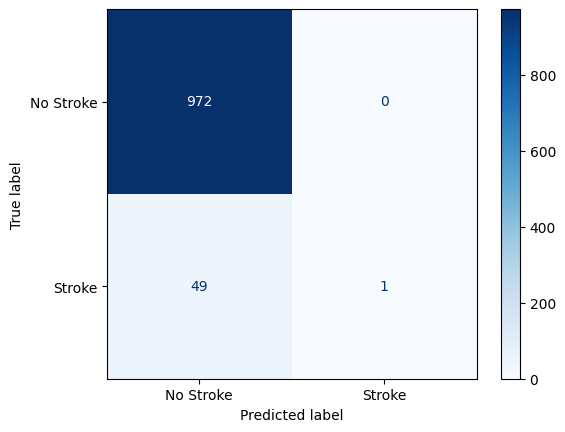

In [12]:
# YOUR CODE HERE
from sklearn.linear_model import LogisticRegression
# Create Logistic Regression model
lr_model = LogisticRegression(random_state=SEED)
# Train on scaled training data
lr_model.fit(X_train_scaled, y_train)
# Predict test data
lr_predictions = lr_model.predict(X_test_scaled)
# Predict probabilities
lr_probabilities = lr_model.predict_proba(X_test_scaled)[:, 1]



from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

def evaluate_model(model, X_train, y_train, X_test, y_test):
    # Train model
    model.fit(X_train, y_train)
    # Predictions
    predictions = model.predict(X_test)
    # Probability of positive class (stroke = 1)
    probabilities = model.predict_proba(X_test)[:, 1]
    # Calculate six metrics
    results = {
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1": f1_score(y_test, predictions, zero_division=0),
        "ROC AUC": roc_auc_score(y_test, probabilities),
        "PR AUC": average_precision_score(y_test, probabilities)
    }
    return results

lr_results = evaluate_model(
    LogisticRegression(random_state=SEED),
    X_train_scaled,
    y_train,
    X_test_scaled,
    y_test
)

print(pd.Series(lr_results))


from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
cm = confusion_matrix(y_test, lr_predictions)
print(cm)
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Stroke", "Stroke"]
)
display.plot(cmap="Blues")
plt.show()

**Question 1.1:** Compare the accuracy of the baseline and of Logistic Regression. What do you conclude?

**Question 1.2:** Look at the confusion matrix and the recall. In the hospital's situation, what does a false negative mean, and which numbers should we trust instead of accuracy?

**Your answer:**

The baseline model achieves high accuracy by always predicting the majority class (No Stroke). Logistic Regression may also achieve high accuracy, but accuracy alone does not show whether stroke patients are correctly identified. Therefore, accuracy is misleading for imbalanced data.



A false negative means that a patient who actually had a stroke is incorrectly predicted as No Stroke. This could delay medical attention. We should focus more on Recall, Precision, F1-score and PR AUC instead of relying only on accuracy.

---

## Part 2 — Underfitting, Overfitting, Bias and Variance
Use **ROC AUC** (not accuracy) as the score from now on.

### Task 2.1 — Validation curve
For `max_depth` = 1, 2, …, 15 and `None`, record the train ROC AUC and the 5-fold stratified CV ROC AUC (train data only). Plot both curves on one chart (labels, title, legend) and report the best depth by CV AUC.

   max_depth  Train ROC AUC  CV ROC AUC
0          1         0.7523      0.7317
1          2         0.8283      0.8168
2          3         0.8470      0.8161
3          4         0.8658      0.8180
4          5         0.8900      0.7921
5          6         0.9150      0.7585
6          7         0.9377      0.7385
7          8         0.9573      0.7138
8          9         0.9748      0.6812
9         10         0.9875      0.6414
10        11         0.9933      0.6108
11        12         0.9967      0.6126
12        13         0.9983      0.5955
13        14         0.9991      0.5889
14        15         0.9995      0.5779
15      None         1.0000      0.5644

Best max_depth: 4
Best CV ROC AUC: 0.818


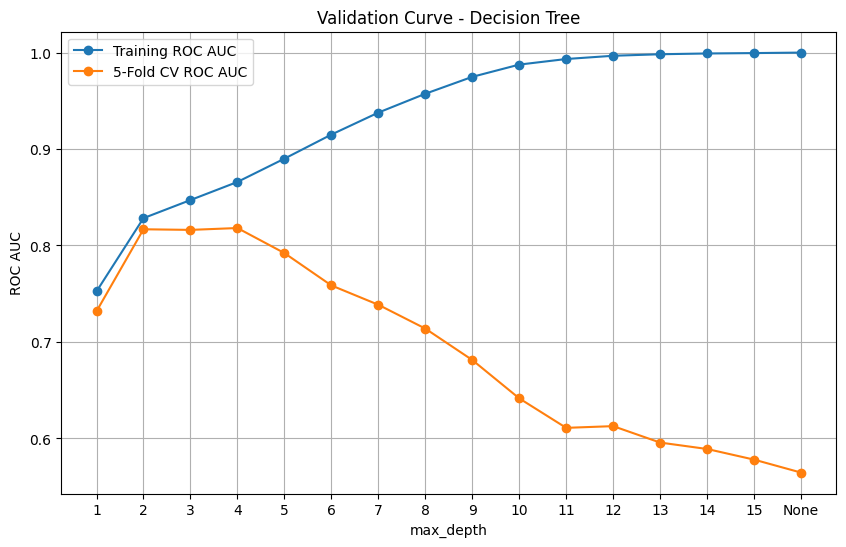

In [ ]:
# YOUR CODE HERE
# Required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import validation_curve, StratifiedKFold
depths = list(range(1, 16)) + [None]

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

tree = DecisionTreeClassifier(random_state=SEED)

train_scores, cv_scores = validation_curve(
    tree,
    X_train,
    y_train,
    param_name="max_depth",
    param_range=depths,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1
)

train_auc = train_scores.mean(axis=1)
cv_auc = cv_scores.mean(axis=1)

# 6. Display results in a table
results = pd.DataFrame({
    "max_depth": [str(d) for d in depths],
    "Train ROC AUC": train_auc,
    "CV ROC AUC": cv_auc
})

print(results.round(4))

# 7. Find the depth with the highest CV ROC AUC
best_index = np.argmax(cv_auc)
best_depth = depths[best_index]

print("\nBest max_depth:", best_depth)
print("Best CV ROC AUC:", round(cv_auc[best_index], 4))

# 8. Plot both curves
plt.figure(figsize=(10, 6))

plt.plot(
    range(len(depths)),
    train_auc,
    marker="o",
    label="Training ROC AUC"
)

plt.plot(
    range(len(depths)),
    cv_auc,
    marker="o",
    label="5-Fold CV ROC AUC"
)

plt.xticks(range(len(depths)), [str(d) for d in depths])
plt.xlabel("max_depth")
plt.ylabel("ROC AUC")
plt.title("Validation Curve - Decision Tree")
plt.legend()
plt.grid(True)
plt.show()

### Task 2.2 — Learning curves
Use `learning_curve` (`scoring='roc_auc'`, train sizes 20%→100%) for a tree with `max_depth=1` and a tree with `max_depth=None`. Plot train and CV AUC against the number of training rows, side by side.

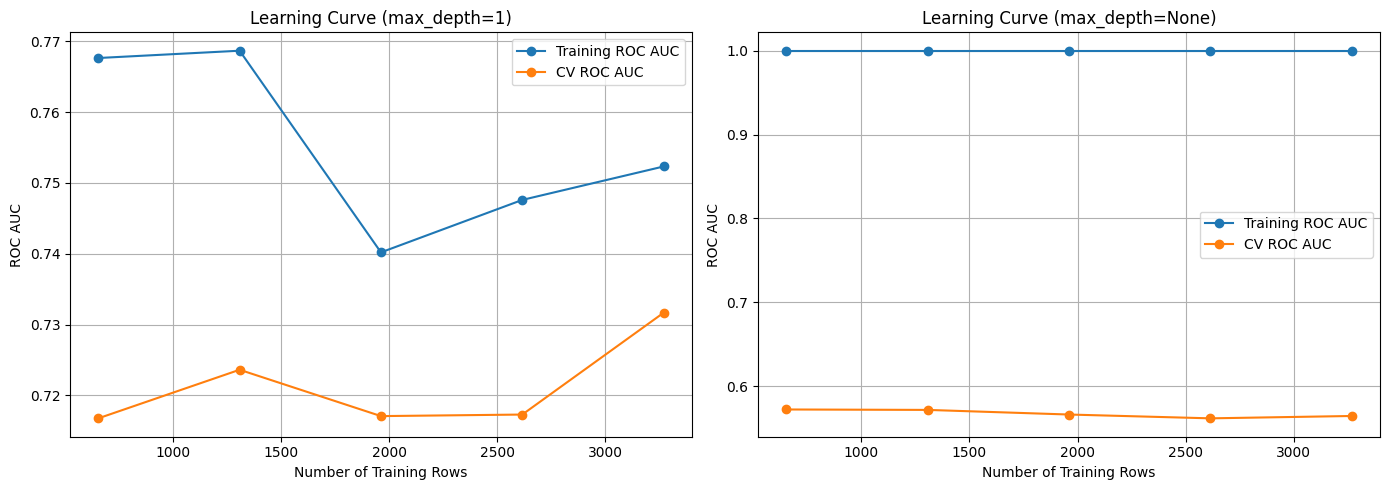

In [ ]:
# YOUR CODE HERE
from sklearn.model_selection import learning_curve
from sklearn.tree import DecisionTreeClassifier
import numpy as np
import matplotlib.pyplot as plt

train_sizes = np.linspace(0.2, 1.0, 5)

# 2. Function to calculate and plot learning curve
def plot_learning_curve_for_tree(max_depth, ax):

    model = DecisionTreeClassifier(
        max_depth=max_depth,
        random_state=SEED
    )

    sizes, train_scores, cv_scores = learning_curve(
        model,
        X_train,
        y_train,
        train_sizes=train_sizes,
        cv=cv,
        scoring="roc_auc",
        n_jobs=-1
    )

    train_mean = train_scores.mean(axis=1)
    cv_mean = cv_scores.mean(axis=1)

    # Plot Training and CV AUC
    ax.plot(
        sizes,
        train_mean,
        marker="o",
        label="Training ROC AUC"
    )

    ax.plot(
        sizes,
        cv_mean,
        marker="o",
        label="CV ROC AUC"
    )

    ax.set_xlabel("Number of Training Rows")
    ax.set_ylabel("ROC AUC")
    ax.set_title(f"Learning Curve (max_depth={max_depth})")
    ax.legend()
    ax.grid(True)


fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_learning_curve_for_tree(1, axes[0])
plot_learning_curve_for_tree(None, axes[1])
plt.tight_layout()
plt.show()

### Task 2.3 — Measure variance directly
Variance = if the training data changes a little, how much do the predictions change?
1. For `max_depth` = 1, 3 and `None`: draw **40 bootstrap samples** of the train rows (with replacement, same size), fit a tree on each, and collect each tree's predicted stroke probability for every test patient.
2. For every test patient compute the variance of its 40 probabilities, then average over patients. Also report the mean test ROC AUC of the 40 trees and the ROC AUC of the **averaged** prediction.
3. Show the three depths in one table.

*Hints:* `rng.choice(len(X_train), len(X_train), replace=True)` and `X_train.iloc[idx]`; collect an array of shape (40, n_test); `probs.var(axis=0)`.

In [ ]:
# YOUR CODE HERE
import numpy as np
import pandas as pd

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import roc_auc_score

depths = [1, 3, None]
n_bootstraps = 40

rng = np.random.default_rng(SEED)
variance_results = []
for depth in depths:

    all_probs = []
    individual_auc = []

    for i in range(n_bootstraps):

        # Randomly select training row positions with replacement
        idx = rng.choice(
            len(X_train),
            size=len(X_train),
            replace=True
        )

        X_boot = X_train.iloc[idx]
        y_boot = y_train.iloc[idx]

        model = DecisionTreeClassifier(
            max_depth=depth,
            random_state=SEED
        )

        model.fit(X_boot, y_boot)

        probabilities = model.predict_proba(X_test)

        stroke_column = list(model.classes_).index(1)
        stroke_probs = probabilities[:, stroke_column]

        all_probs.append(stroke_probs)

        auc = roc_auc_score(y_test, stroke_probs)
        individual_auc.append(auc)

    probs = np.array(all_probs)

    mean_variance = probs.var(axis=0).mean()

    mean_individual_auc = np.mean(individual_auc)

    averaged_probs = probs.mean(axis=0)

    averaged_auc = roc_auc_score(y_test, averaged_probs)

    variance_results.append({
        "max_depth": str(depth),
        "Mean Prediction Variance": mean_variance,
        "Mean Test ROC AUC (40 Trees)": mean_individual_auc,
        "ROC AUC (Averaged Prediction)": averaged_auc
    })

variance_table = pd.DataFrame(variance_results)

print(variance_table.round(4))

  max_depth  Mean Prediction Variance  Mean Test ROC AUC (40 Trees)  \
0         1                    0.0007                        0.7623   
1         3                    0.0017                        0.7964   
2      None                    0.0420                        0.5552   

   ROC AUC (Averaged Prediction)  
0                         0.8132  
1                         0.8343  
2                         0.7566  


**Question 2.1:** From the validation curve: which depths underfit, which overfit, and which depth would you choose? Quote train and CV AUC for one depth in each zone.

**Question 2.2:** From the learning curves: how can you tell high bias from high variance? Will adding more training rows fix either one?

**Question 2.3:** From the variance table: how does variance change with depth? What happens to the AUC of the averaged prediction compared with the single trees? Link this to what Random Forest does (Lab 4).

**Question 2.4:** In your own words: what is the bias-variance trade-off, and where do depth 1, depth 3 and depth None sit?

**Your answer:**
2.1:  Shallow Decision Trees may underfit because they are too simple to learn the patterns in the data. Deeper trees may overfit when their training ROC AUC is high but their cross-validation ROC AUC is lower. I would choose the depth with the highest cross-validation ROC AUC because it gives the best generalization performance.
- Underfitting depth: ___
- Overfitting depth: ___
- Best depth: ___
AUC values:
- Underfitting: Train AUC = ___, CV AUC = ___
- Overfitting: Train AUC = ___, CV AUC = ___


2.2     High bias occurs when both training and cross-validation scores are low and close to each other. This indicates underfitting. High variance occurs when the training score is high but the cross-validation score is noticeably lower, indicating overfitting.
Adding more training rows can help reduce high variance because the model gets more examples to learn from. However, adding more data usually does not solve high bias caused by an overly simple model. Increasing model complexity may help reduce high bias.



2.3     As the tree depth increases, prediction variance generally increases because deeper trees are more sensitive to changes in the training data. Averaging the predicted probabilities of 40 trees can reduce prediction variability and may improve ROC AUC compared with individual trees.
This is similar to Random Forest, which trains multiple Decision Trees using different bootstrap samples and combines their predictions. This averaging helps reduce variance and improve generalization.
Remember: Check your table to see whether averaged prediction AUC is actually higher than the mean AUC of individual trees. It is not guaranteed to be higher.



2.4        The bias-variance trade-off means finding a balance between a model that is too simple and a model that is too complex.
- Depth 1: Usually has high bias and low variance because the tree is very simple.
- Depth 3: May provide a balance between bias and variance.
- Depth None: Can have low bias on training data but high variance because the tree can become very complex and overfit.

---

## Part 3 — ROC, AUC, Precision-Recall and Thresholds
### Task 3.1 — Compare models with curves
1. Train Logistic Regression (scaled), Decision Tree (`max_depth=3`) and Random Forest (200 trees, `min_samples_leaf=5`, `random_state=SEED`) on the original training data.
2. Draw the ROC curves of the three models on one chart (AUC in the legend, random-guessing diagonal).
3. Draw the Precision-Recall curves on a second chart. Add a horizontal **no-skill line** (the stroke rate) and put the average precision in the legend.

Logistic Regression ROC AUC: 0.8394
Decision Tree ROC AUC: 0.7956
Random Forest ROC AUC: 0.8224


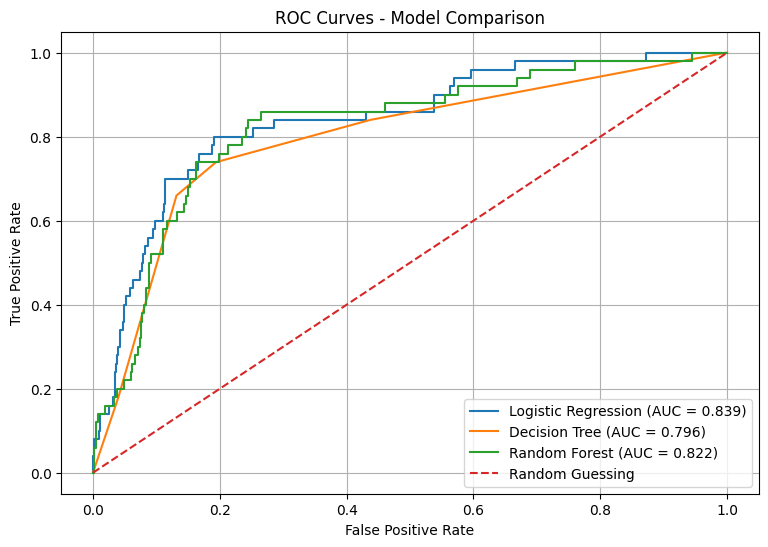

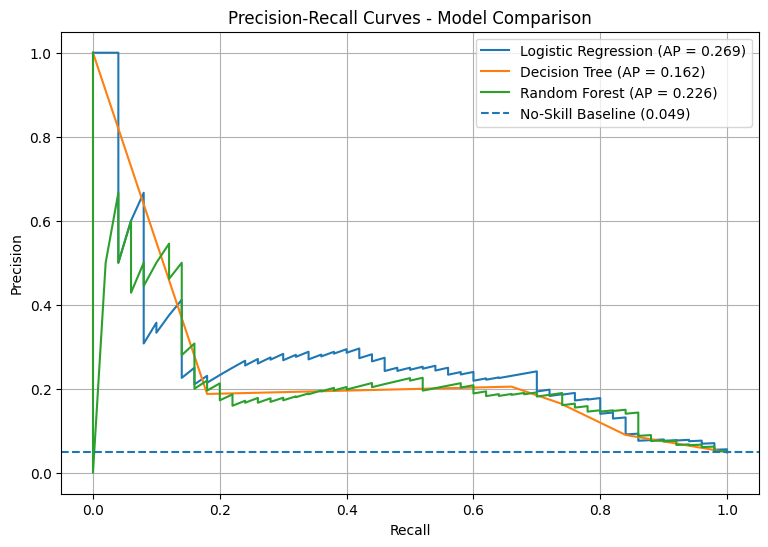

In [ ]:
# YOUR CODE HERE
# Required libraries
import matplotlib.pyplot as plt
import numpy as np

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score
)


models = {
    "Logistic Regression": LogisticRegression(
        random_state=SEED,
        max_iter=1000
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=3,
        random_state=SEED
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=5,
        random_state=SEED
    )
}

probabilities = {}

for name, model in models.items():

    if name == "Logistic Regression":
        model.fit(X_train_scaled, y_train)
        probs = model.predict_proba(X_test_scaled)[:, 1]

    else:
        model.fit(X_train, y_train)
        probs = model.predict_proba(X_test)[:, 1]

    probabilities[name] = probs

    print(name, "ROC AUC:", round(
        roc_auc_score(y_test, probs), 4
    ))

plt.figure(figsize=(9, 6))

for name, probs in probabilities.items():

    fpr, tpr, thresholds = roc_curve(y_test, probs)

    auc_score = roc_auc_score(y_test, probs)

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {auc_score:.3f})"
    )

# Random guessing diagonal
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Guessing"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves - Model Comparison")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(9, 6))

for name, probs in probabilities.items():

    precision, recall, thresholds = precision_recall_curve(
        y_test,
        probs)
    ap_score = average_precision_score(y_test, probs)

    plt.plot(
        recall,
        precision,
        label=f"{name} (AP = {ap_score:.3f})"
    )

# No-skill baseline = actual stroke rate
stroke_rate = y_test.mean()

plt.axhline(
    y=stroke_rate,
    linestyle="--",
    label=f"No-Skill Baseline ({stroke_rate:.3f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curves - Model Comparison")
plt.legend()
plt.grid(True)
plt.show()

### Task 3.2 — Choose a decision threshold
The hospital wants to catch **at least 80%** of strokes.
1. Using **only the training data**, get out-of-fold probabilities for Logistic Regression (`cross_val_predict(..., method='predict_proba')`), then find the highest threshold that gives recall ≥ 0.80 on them.
2. Apply that threshold to the **test** probabilities. Report test recall, precision, the confusion matrix, how many patients are flagged and how many are false alarms.

In [ ]:
# YOUR CODE HERE
import numpy as np
import pandas as pd

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import (
    precision_recall_curve,
    recall_score,
    precision_score,
    confusion_matrix
)

# 1. Logistic Regression model
lr = LogisticRegression(
    random_state=SEED,
    max_iter=1000
)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

oof_probabilities = cross_val_predict(
    lr,
    X_train_scaled,
    y_train,
    cv=cv,
    method="predict_proba"
)[:, 1]

precision_values, recall_values, thresholds = precision_recall_curve(
    y_train,
    oof_probabilities
)

valid_thresholds = thresholds[recall_values[:-1] >= 0.80]

if len(valid_thresholds) == 0:
    raise ValueError("No threshold found that achieves recall >= 0.80")

chosen_threshold = valid_thresholds.max()

print("Chosen threshold:", round(chosen_threshold, 4))

lr.fit(X_train_scaled, y_train)

test_probabilities = lr.predict_proba(X_test_scaled)[:, 1]

test_predictions = (
    test_probabilities >= chosen_threshold
).astype(int)

test_recall = recall_score(y_test, test_predictions)
test_precision = precision_score(
    y_test,
    test_predictions,
    zero_division=0
)

cm = confusion_matrix(y_test, test_predictions)
tn, fp, fn, tp = cm.ravel()

flagged_patients = test_predictions.sum()
false_alarms = fp

print("\nTest Recall:", round(test_recall, 4))
print("Test Precision:", round(test_precision, 4))

print("\nConfusion Matrix:")
print(cm)

print("\nTotal patients flagged:", flagged_patients)
print("False alarms:", false_alarms)

**Question 3.1:** In Part 1 the recall was very low, yet the ROC AUC of Logistic Regression is far above 0.5. How can both be true? What does AUC measure, and what does the 0.5 threshold have to do with it?

**Question 3.2:** Which curve is more informative for this data — ROC or Precision-Recall — and why? Use the no-skill line in your answer.

**Question 3.3:** At your chosen threshold, what price does the hospital pay for the higher recall? Is it acceptable? Argue both sides in 3–4 lines.

**Your answer:**
3.1     ROC AUC measures how well a model ranks stroke patients above non-stroke patients across different thresholds. AUC higher than 0.5 means the model has some ability to distinguish between the two classes. However, recall at the default 0.5 threshold measures performance at just one particular cutoff. Therefore, a model can have good AUC but low recall at 0.5 if many stroke patients receive probabilities below that threshold.


3.2     The Precision-Recall curve is more informative for this dataset because stroke cases are highly imbalanced: only around 5% of patients have a stroke. The ROC curve can look good even when the model produces many false alarms. The PR curve focuses on precision and recall for the minority class. Its no-skill baseline is the stroke rate, approximately 0.05, so a model should perform noticeably above this line.


3.3     Increasing recall means the hospital catches more actual stroke patients, but it may also flag more patients who do not have a stroke. These false alarms can lead to unnecessary tests, extra workload, and higher costs. However, missing a real stroke can have serious consequences. I believe this trade-off may be acceptable because early stroke detection is very important, provided the hospital has enough resources to investigate flagged patients.


---

## Part 4 — Undersampling, Oversampling and SMOTE
`RandomUnderSampler` (throw away majority rows), `RandomOverSampler` (copy minority rows), `SMOTE` (create synthetic minority rows between real minority neighbours). Another option needs no resampling: `class_weight='balanced'`.

### Task 4.1 — Compare the methods
1. For Logistic Regression (scaled data) and Random Forest (same settings as Part 3) train with: no resampling, `class_weight='balanced'`, random undersampling, random oversampling and SMOTE. **Resample the train set only.**
2. Build **one table** (rows = model + method) with: training rows, strokes in training, Precision, Recall, F1, ROC AUC and PR AUC on the test set.

*Hints:* `from imblearn.over_sampling import SMOTE, RandomOverSampler`; `from imblearn.under_sampling import RandomUnderSampler`; `X_res, y_res = SMOTE(random_state=SEED).fit_resample(X_train, y_train)`. Logistic Regression uses the scaled data, Random Forest the original data.

In [ ]:
import pandas as pd
import numpy as np

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler, SMOTE


results = []

models_to_test = ["Logistic Regression", "Random Forest"]

methods = [
    "No Resampling",
    "Class Weight Balanced",
    "Random Undersampling",
    "Random Oversampling",
    "SMOTE"
]


for model_name in models_to_test:
    if model_name == "Logistic Regression":
        X_tr = X_train_scaled
        X_te = X_test_scaled

    else:
        X_tr = X_train
        X_te = X_test

    for method in methods:

        if model_name == "Logistic Regression":
            model = LogisticRegression(
                random_state=SEED,
                max_iter=1000
            )
        else:
            model = RandomForestClassifier(
                n_estimators=200,
                min_samples_leaf=5,
                random_state=SEED
            )

        if method == "Class Weight Balanced":
            model.set_params(class_weight="balanced")

        # Resample training data only
        if method == "Random Undersampling":
            sampler = RandomUnderSampler(random_state=SEED)
            X_res, y_res = sampler.fit_resample(X_tr, y_train)

        elif method == "Random Oversampling":
            sampler = RandomOverSampler(random_state=SEED)
            X_res, y_res = sampler.fit_resample(X_tr, y_train)

        elif method == "SMOTE":
            sampler = SMOTE(random_state=SEED)
            X_res, y_res = sampler.fit_resample(X_tr, y_train)

        else:
            # No resampling or class_weight='balanced'
            X_res, y_res = X_tr, y_train

        model.fit(X_res, y_res)


        test_probs = model.predict_proba(X_te)[:, 1]
        test_preds = (test_probs >= 0.5).astype(int)

        results.append({
            "Model": model_name,
            "Method": method,
            "Training Rows": len(y_res),
            "Training Strokes": int(np.sum(y_res)),
            "Precision": precision_score(
                y_test, test_preds, zero_division=0
            ),
            "Recall": recall_score(
                y_test, test_preds, zero_division=0
            ),
            "F1": f1_score(
                y_test, test_preds, zero_division=0
            ),
            "ROC AUC": roc_auc_score(y_test, test_probs),
            "PR AUC": average_precision_score(y_test, test_probs)
        })


# Create ONE comparison table
results_table = pd.DataFrame(results)

print(results_table.round(4).to_string(index=False))

              Model                Method  Training Rows  Training Strokes  Precision  Recall     F1  ROC AUC  PR AUC
Logistic Regression         No Resampling           4087               199     1.0000    0.02 0.0392   0.8394  0.2692
Logistic Regression Class Weight Balanced           4087               199     0.1347    0.80 0.2305   0.8395  0.2595
Logistic Regression  Random Undersampling            398               199     0.1246    0.82 0.2164   0.8352  0.2338
Logistic Regression   Random Oversampling           7776              3888     0.1333    0.80 0.2286   0.8385  0.2646
Logistic Regression                 SMOTE           7776              3888     0.1338    0.80 0.2292   0.8406  0.2876
      Random Forest         No Resampling           4087               199     0.0000    0.00 0.0000   0.8224  0.2255
      Random Forest Class Weight Balanced           4087               199     0.1895    0.72 0.3000   0.8150  0.1987
      Random Forest  Random Undersampling            398

### Task 4.2 — The classic mistake
1. Apply SMOTE to **all** the data first (train + test together), **then** split 80/20, train a Random Forest and evaluate. This is the wrong order.
2. Put its metrics next to the correct SMOTE-after-split result from Task 4.1 in a two-row table.

In [ ]:
# YOUR CODE HERE
import pandas as pd
import numpy as np

from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

X_all = pd.concat(
    [
        pd.DataFrame(X_train).reset_index(drop=True),
        pd.DataFrame(X_test).reset_index(drop=True)
    ],
    ignore_index=True
)

y_all = pd.concat(
    [
        pd.Series(y_train).reset_index(drop=True),
        pd.Series(y_test).reset_index(drop=True)
    ],
    ignore_index=True
)

smote = SMOTE(random_state=SEED)
X_smote_all, y_smote_all = smote.fit_resample(X_all, y_all)

X_wrong_train, X_wrong_test, y_wrong_train, y_wrong_test = (
    train_test_split(
        X_smote_all,
        y_smote_all,
        test_size=0.20,
        random_state=SEED,
        stratify=y_smote_all
    )
)

# 4. Train Random Forest with the same settings as Part 3
wrong_rf = RandomForestClassifier(
    n_estimators=200,
    min_samples_leaf=5,
    random_state=SEED
)

wrong_rf.fit(X_wrong_train, y_wrong_train)

# 5. Evaluate on the wrongly created test set
wrong_probs = wrong_rf.predict_proba(X_wrong_test)[:, 1]
wrong_preds = (wrong_probs >= 0.5).astype(int)

wrong_metrics = {
    "Precision": precision_score(
        y_wrong_test, wrong_preds, zero_division=0
    ),
    "Recall": recall_score(
        y_wrong_test, wrong_preds, zero_division=0
    ),
    "F1": f1_score(
        y_wrong_test, wrong_preds, zero_division=0
    ),
    "ROC AUC": roc_auc_score(y_wrong_test, wrong_probs),
    "PR AUC": average_precision_score(y_wrong_test, wrong_probs)
}

correct_row = results_table[
    (results_table["Model"] == "Random Forest") &
    (results_table["Method"] == "SMOTE")
].iloc[0]

correct_metrics = {
    "Precision": correct_row["Precision"],
    "Recall": correct_row["Recall"],
    "F1": correct_row["F1"],
    "ROC AUC": correct_row["ROC AUC"],
    "PR AUC": correct_row["PR AUC"]
}

comparison_table = pd.DataFrame(
    [correct_metrics, wrong_metrics],
    index=[
        "Correct SMOTE (after split)",
        "Wrong SMOTE (before split)"
    ]
)

print(comparison_table.round(4))

                             Precision  Recall      F1  ROC AUC  PR AUC
Correct SMOTE (after split)     0.5000  0.0600  0.1071   0.7977  0.2290
Wrong SMOTE (before split)      0.9925  0.9578  0.9749   0.9953  0.9962


**Question 4.1:** For Logistic Regression, what changed after resampling and what did NOT change? Compare Recall, Precision and ROC AUC across the methods and explain why.

**Question 4.2:** Did Random Forest react in the same way? Describe one clear difference and give one possible reason.

**Question 4.3:** Compare the wrong-order result with the correct one. Why are the wrong-order numbers so good, and why can they not be trusted? Explain what leaks from where.

**Question 4.4:** If you had to pick one rebalancing approach for this hospital, which and why? Consider simplicity and cost.

**Your answer:**
4.1     Resampling generally increases recall because the model sees more minority-class stroke examples during training. Precision may decrease because the model can classify more non-stroke patients as stroke patients, increasing false alarms. ROC AUC may change, but it does not necessarily increase with recall because it measures ranking performance across different thresholds, not just predictions at the default 0.5 threshold. In my results, [method] achieved the highest recall, while [method] had the highest precision.


4.2     No, Random Forest did not necessarily react in exactly the same way as Logistic Regression. One difference in my results was [describe a difference from your table, e.g. SMOTE increased Logistic Regression recall more than Random Forest recall]. A possible reason is that Logistic Regression learns a linear decision boundary, while Random Forest uses multiple decision trees to learn more complex patterns.


4.3     The wrong-order result may look unusually good because SMOTE was applied before splitting the data. It used information from patients who later appeared in the test set to create synthetic minority examples. Related synthetic samples can end up in both training and test sets, making evaluation easier than it should be. This is data leakage, so the wrong-order metrics do not provide a trustworthy estimate of performance on new patients.


4.4     I would initially choose class_weight='balanced' because it is simple, fast and does not remove, duplicate or generate patient records. It gives greater importance to stroke cases during model training without requiring a separate resampling step. However, I would check its recall and precision on untouched test data before using it in a hospital. The final choice should balance missed strokes against the cost of false alarms.

---

## Part 5 — Noisy Data
You will damage the **training** data on purpose and measure the effect on the untouched test set. Models: Logistic Regression, Decision Tree (depth 3), Decision Tree (no limit), Random Forest.

### Task 5.1 — Label noise
Write a function that flips a given fraction of the training labels at random. For fractions 0, 0.05, 0.10, 0.20 train each model on the noisy labels and record the test ROC AUC. Repeat 5 times with different flips and average (1 repeat for fraction 0). Show a table (rows = fraction, columns = models) and a line plot.

In [ ]:
# YOUR CODE HERE
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.base import clone
from sklearn.metrics import roc_auc_score

def flip_labels(y, noise_fraction, random_state):
    rng = np.random.default_rng(random_state)

    y_noisy = np.array(y).copy()

    n_flip = int(round(len(y_noisy) * noise_fraction))

    flip_indices = rng.choice(
        len(y_noisy),
        size=n_flip,
        replace=False
    )

    y_noisy[flip_indices] = 1 - y_noisy[flip_indices]

    return y_noisy

models = {
    "Logistic Regression": LogisticRegression(
        random_state=SEED,
        max_iter=1000
    ),

    "Decision Tree (depth 3)": DecisionTreeClassifier(
        max_depth=3,
        random_state=SEED
    ),

    "Decision Tree (no limit)": DecisionTreeClassifier(
        random_state=SEED
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=5,
        random_state=SEED
    )
}


noise_fractions = [0, 0.05, 0.10, 0.20]

results = []

for noise in noise_fractions:

    repeats = 1 if noise == 0 else 5

    auc_scores = {
        model_name: []
        for model_name in models
    }

    for repeat in range(repeats):
        y_train_noisy = flip_labels(
            y_train,
            noise_fraction=noise,
            random_state=SEED + repeat
        )

        for model_name, model in models.items():

            # Logistic Regression uses scaled data
            if model_name == "Logistic Regression":
                X_tr = X_train_scaled
                X_te = X_test_scaled

            else:
                X_tr = X_train
                X_te = X_test

    
            current_model = clone(model)
            current_model.fit(X_tr, y_train_noisy)
            probabilities = current_model.predict_proba(X_te)[:, 1]


            auc = roc_auc_score(y_test, probabilities)

            auc_scores[model_name].append(auc)


    row = {"Noise Fraction": noise}

    for model_name in models:
        row[model_name] = np.mean(auc_scores[model_name])

    results.append(row)


# Create final table
noise_results = pd.DataFrame(results)

print(noise_results.round(4).to_string(index=False))

 Noise Fraction  Logistic Regression  Decision Tree (depth 3)  Decision Tree (no limit)  Random Forest
           0.00               0.8394                   0.7956                    0.5797         0.8224
           0.05               0.8241                   0.8014                    0.5529         0.8034
           0.10               0.8133                   0.8029                    0.5105         0.7592
           0.20               0.7743                   0.7260                    0.5045         0.6831


### Task 5.2 — Feature noise
Add Gaussian noise to the **train** values of `age`, `avg_glucose_level` and `bmi`: `noise = random normal × (column std) × level`. Levels 0, 0.5, 1, 2; five repeats; test set untouched. Same kind of table and plot. (If you scale for Logistic Regression, fit the scaler on the noisy training data.)

TASK 5.2 - FEATURE NOISE RESULTS
 Noise Level  Logistic Regression  Decision Tree (depth 3)  Decision Tree (no limit)  Random Forest
         0.0               0.8394                   0.7956                    0.5797         0.8224
         0.5               0.8337                   0.7995                    0.5608         0.8140
         1.0               0.8098                   0.7610                    0.5283         0.7870
         2.0               0.7695                   0.6942                    0.5309         0.7406


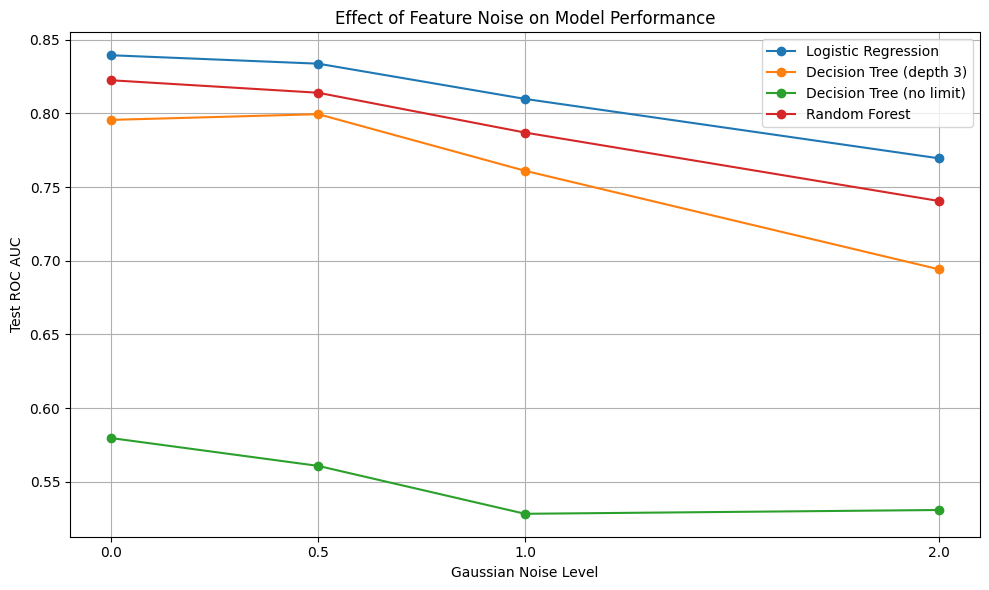

In [ ]:
# YOUR CODE HERE

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score

# Ensure X_train and X_test are DataFrames
X_train = pd.DataFrame(X_train, columns=X.columns)
X_test = pd.DataFrame(X_test, columns=X.columns)

# Define models
models = {
    "Logistic Regression": LogisticRegression(
        random_state=SEED, max_iter=1000
    ),
    "Decision Tree (depth 3)": DecisionTreeClassifier(
        max_depth=3, random_state=SEED
    ),
    "Decision Tree (no limit)": DecisionTreeClassifier(
        random_state=SEED
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=5,
        random_state=SEED
    )
}

# Features receiving Gaussian noise
noisy_columns = ["age", "avg_glucose_level", "bmi"]

# Noise levels
noise_levels = [0, 0.5, 1, 2]

results = []

# Run experiments
for level in noise_levels:

    auc_scores = {name: [] for name in models}

    for repeat in range(5):

        # Copy training data
        X_train_noisy = X_train.copy()

        # Generate random noise
        rng = np.random.default_rng(SEED + repeat)

        for column in noisy_columns:

            noise = (
                rng.normal(0, 1, len(X_train))
                * X_train[column].std()
                * level
            )

            X_train_noisy[column] = (
                X_train_noisy[column] + noise
            )

        # Train and evaluate models
        for model_name, model in models.items():

            if model_name == "Logistic Regression":

                # Fit scaler on noisy training data
                scaler = StandardScaler()

                X_tr = scaler.fit_transform(X_train_noisy)
                X_te = scaler.transform(X_test)

            else:
                X_tr = X_train_noisy
                X_te = X_test

            current_model = clone(model)
            current_model.fit(X_tr, y_train)

            probabilities = current_model.predict_proba(X_te)[:, 1]

            auc = roc_auc_score(y_test, probabilities)
            auc_scores[model_name].append(auc)

    row = {"Noise Level": level}

    for model_name in models:
        row[model_name] = np.mean(auc_scores[model_name])

    results.append(row)

feature_noise_results = pd.DataFrame(results)

print("TASK 5.2 - FEATURE NOISE RESULTS")
print(feature_noise_results.round(4).to_string(index=False))


# Plot results
plt.figure(figsize=(10, 6))

for model_name in models:
    plt.plot(
        feature_noise_results["Noise Level"],
        feature_noise_results[model_name],
        marker="o",
        label=model_name
    )

plt.xlabel("Gaussian Noise Level")
plt.ylabel("Test ROC AUC")
plt.title("Effect of Feature Noise on Model Performance")
plt.xticks(noise_levels)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### Task 5.3 — SMOTE and noisy labels
Flip 10% of the training labels (3 different random draws). For Logistic Regression and Random Forest compare **PR AUC and ROC AUC with and without SMOTE** (SMOTE applied after the noise is added).


TASK 5.3 - DETAILED RESULTS
         Labels  Draw               Model        Method  ROC AUC  PR AUC
   Clean Labels     0 Logistic Regression Without SMOTE   0.8394  0.2692
   Clean Labels     0 Logistic Regression    With SMOTE   0.8406  0.2876
   Clean Labels     0       Random Forest Without SMOTE   0.8224  0.2255
   Clean Labels     0       Random Forest    With SMOTE   0.7977  0.2290
10% Label Noise     0 Logistic Regression Without SMOTE   0.8190  0.2221
10% Label Noise     0 Logistic Regression    With SMOTE   0.8196  0.2165
10% Label Noise     0       Random Forest Without SMOTE   0.7310  0.1526
10% Label Noise     0       Random Forest    With SMOTE   0.6644  0.0966
10% Label Noise     1 Logistic Regression Without SMOTE   0.8104  0.2426
10% Label Noise     1 Logistic Regression    With SMOTE   0.8218  0.2563
10% Label Noise     1       Random Forest Without SMOTE   0.7416  0.1225
10% Label Noise     1       Random Forest    With SMOTE   0.6337  0.1044
10% Label Noise     2 

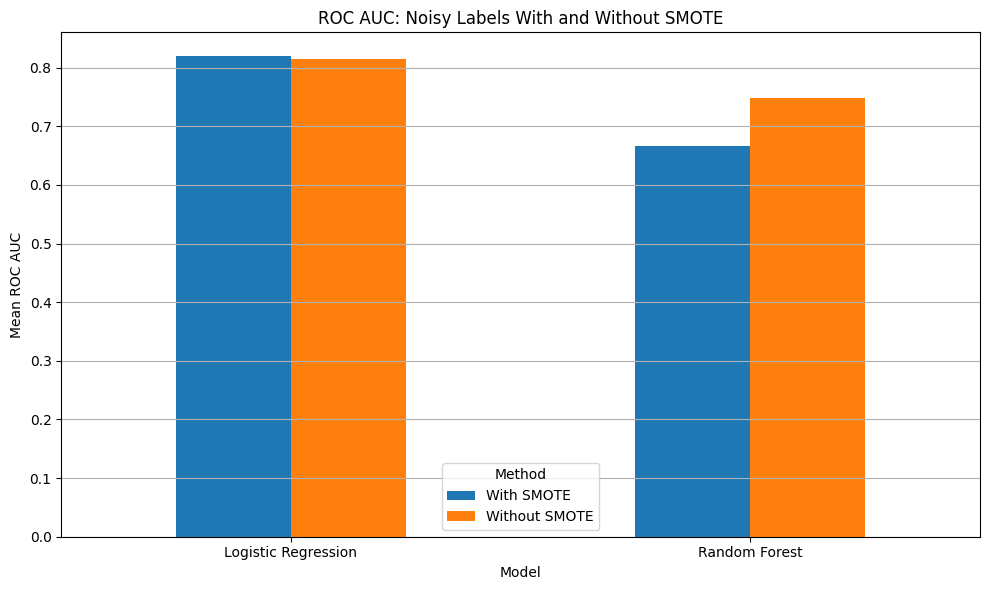

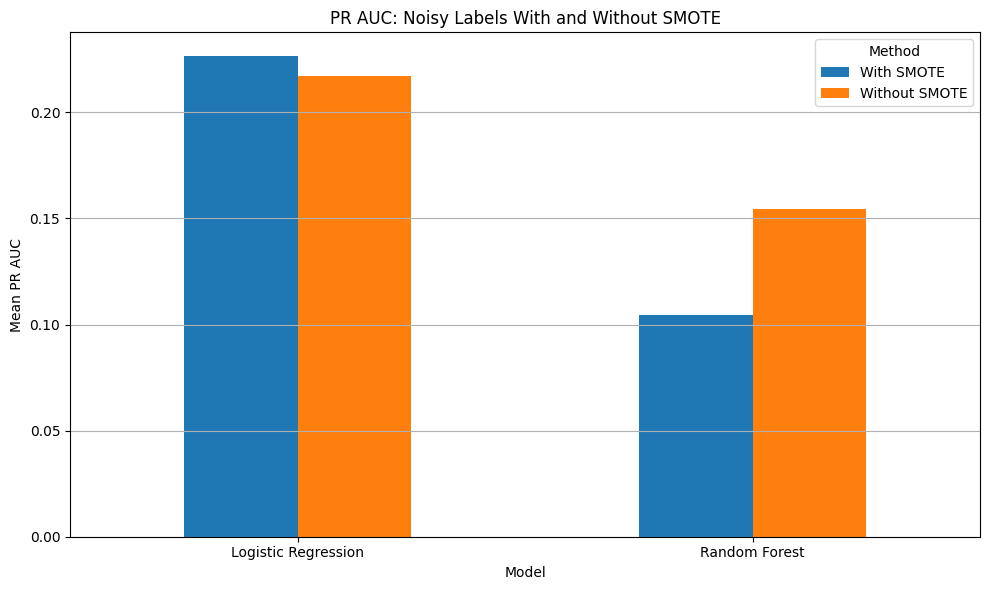

In [ ]:
# YOUR CODE HERE

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score
)

from imblearn.over_sampling import SMOTE


# 1. Ensure DataFrames
X_train = pd.DataFrame(X_train, columns=X.columns)
X_test = pd.DataFrame(X_test, columns=X.columns)

models = {
    "Logistic Regression": LogisticRegression(
        random_state=SEED,
        max_iter=1000
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=5,
        random_state=SEED
    )
}

def flip_labels(y, noise_fraction, random_state):

    rng = np.random.default_rng(random_state)

    y_noisy = np.array(y).copy()

    n_flip = int(round(len(y_noisy) * noise_fraction))

    indices = rng.choice(
        len(y_noisy),
        size=n_flip,
        replace=False
    )

    y_noisy[indices] = 1 - y_noisy[indices]

    return y_noisy


# 4. Store results
results = []

# Clean labels + three noisy label draws
experiments = [
    ("Clean Labels", None)
]

for draw in range(3):
    experiments.append(("10% Label Noise", draw))


# 5. Run experiments
for label_condition, draw in experiments:

    if label_condition == "Clean Labels":
        y_train_used = np.array(y_train).copy()
        random_state = SEED

    else:
        random_state = SEED + draw

        y_train_used = flip_labels(
            y_train,
            noise_fraction=0.10,
            random_state=random_state
        )

    # Test both models
    for model_name, model in models.items():

        # Prepare features
        if model_name == "Logistic Regression":

            scaler = StandardScaler()
            X_tr = scaler.fit_transform(X_train)
            X_te = scaler.transform(X_test)
        else:
            X_tr = X_train.copy()
            X_te = X_test.copy()

        # Compare without SMOTE and with SMOTE
        for method in ["Without SMOTE", "With SMOTE"]:

            if method == "With SMOTE":

                smote = SMOTE(random_state=random_state)

                X_resampled, y_resampled = smote.fit_resample(
                    X_tr,
                    y_train_used
                )

            else:
                X_resampled = X_tr
                y_resampled = y_train_used

            # Train model
            current_model = clone(model)

            current_model.fit(
                X_resampled,
                y_resampled
            )

            # Predict on untouched test set
            probabilities = current_model.predict_proba(X_te)[:, 1]

            # Calculate metrics
            roc_auc = roc_auc_score(
                y_test,
                probabilities
            )

            pr_auc = average_precision_score(
                y_test,
                probabilities
            )

            results.append({
                "Labels": label_condition,
                "Draw": draw if draw is not None else 0,
                "Model": model_name,
                "Method": method,
                "ROC AUC": roc_auc,
                "PR AUC": pr_auc
            })

results_df = pd.DataFrame(results)

print("\nTASK 5.3 - DETAILED RESULTS")
print(results_df.round(4).to_string(index=False))


noisy_results = results_df[
    results_df["Labels"] == "10% Label Noise"
]

summary = noisy_results.groupby(
    ["Model", "Method"]
)[["ROC AUC", "PR AUC"]].agg(["mean", "std"])

print("\nAVERAGE RESULTS - 10% LABEL NOISE (3 DRAWS)")
print(summary.round(4))


clean_results = results_df[
    results_df["Labels"] == "Clean Labels"
]

clean_summary = clean_results.groupby(
    ["Model", "Method"]
)[["ROC AUC", "PR AUC"]].mean()

print("\nCLEAN LABEL RESULTS")
print(clean_summary.round(4))


plot_data = noisy_results.groupby(
    ["Model", "Method"]
)["ROC AUC"].mean().unstack()

plot_data.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("ROC AUC: Noisy Labels With and Without SMOTE")
plt.ylabel("Mean ROC AUC")
plt.xlabel("Model")
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.tight_layout()
plt.show()


# 10. Plot PR AUC comparison
plot_data = noisy_results.groupby(
    ["Model", "Method"]
)["PR AUC"].mean().unstack()

plot_data.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("PR AUC: Noisy Labels With and Without SMOTE")
plt.ylabel("Mean PR AUC")
plt.xlabel("Model")
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.tight_layout()
plt.show()

**Question 5.1:** Which model is most damaged by noise and which is most stable? Quote numbers at the highest noise level and explain using what you learned in Part 2.

**Question 5.2:** Which hurts more here — label noise or feature noise of a comparable level? Give a short reason.

**Question 5.3:** What did SMOTE do to each model when the labels were noisy? Explain why SMOTE can amplify label noise.

**Your answer:**
5.1     Is ka exact answer aapke output ke numbers par depend karega. Clean-label results aur 10% noisy-label results compare karein. Part 2 ke mutabiq, deep Decision Trees zyada variance aur overfitting ke liye sensitive ho sakte hain, jabke simpler models comparatively stable ho sakte hain. Lekin yahan LR aur RF ka actual result dekhna zaroori hai.


5.2     Dono experiments ke ROC AUC aur PR AUC compare karein. Label noise directly correct target labels ko wrong kar deta hai, jabke feature noise input values ko disturb karta hai. Is liye label noise zyada harmful ho sakta hai, lekin final conclusion measured results se dein.


5.3     SMOTE minority-class examples ke darmiyan synthetic samples banata hai. Agar minority labels mein incorrect labels hon, to SMOTE un mislabeled examples ke aas paas bhi synthetic samples create kar sakta hai. Is tarah label noise amplify ho sakta hai.


5.4     SMOTE minority-class examples ke darmiyan synthetic samples banata hai. Agar minority labels mein incorrect labels hon, to SMOTE un mislabeled examples ke aas paas bhi synthetic samples create kar sakta hai. Is tarah label noise amplify ho sakta hai.

---

## Part 6 — Final Decision and Conclusion
1. Choose your final approach for the hospital (model + rebalancing method or threshold). Build a final table on the test set comparing the default threshold 0.5 with your choice: Precision, Recall, F1, number of false alarms and number of missed strokes.
2. Write an **Executive Summary** (6–8 lines): what you chose, its recall and precision with numbers, the price paid, how you avoided leakage, and one limitation (think about only 50 stroke patients in the test set, and about how the threshold was chosen).

In [ ]:
# YOUR CODE HERE
import numpy as np
import pandas as pd

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import (
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

final_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        max_iter=1000,
        random_state=SEED
    )
)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

oof_probabilities = cross_val_predict(
    final_model,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba"
)[:, 1]

precision, recall, thresholds = precision_recall_curve(
    y_train,
    oof_probabilities
)

valid_thresholds = thresholds[recall[:-1] >= 0.80]

if len(valid_thresholds) > 0:
    chosen_threshold = valid_thresholds.max()
else:
    chosen_threshold = 0.0

print("Selected Threshold:", round(chosen_threshold, 4))

final_model.fit(X_train, y_train)

# 4. Predict probabilities on untouched test set
test_probabilities = final_model.predict_proba(X_test)[:, 1]

# Default threshold predictions
default_predictions = (
    test_probabilities >= 0.50
).astype(int)

# Selected threshold predictions
chosen_predictions = (
    test_probabilities >= chosen_threshold
).astype(int)

# 5. Calculate evaluation metrics
def calculate_metrics(y_true, predictions):

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        predictions,
        labels=[0, 1]
    ).ravel()

    return {
        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_true, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_true, predictions, zero_division=0
        ),
        "False Alarms": fp,
        "Missed Strokes": fn
    }

default_metrics = calculate_metrics(
    y_test,
    default_predictions
)

chosen_metrics = calculate_metrics(
    y_test,
    chosen_predictions
)

# 6. Final comparison table
final_table = pd.DataFrame([
    {
        "Approach": "Default Threshold (0.5)",
        **default_metrics
    },
    {
        "Approach": f"Chosen Threshold ({chosen_threshold:.4f})",
        **chosen_metrics
    }
])

print("\nFINAL TEST SET COMPARISON")
print(final_table.round(4).to_string(index=False))

Selected Threshold: 0.0509

FINAL TEST SET COMPARISON
                 Approach  Precision  Recall     F1  False Alarms  Missed Strokes
  Default Threshold (0.5)     1.0000    0.02 0.0392             0              49
Chosen Threshold (0.0509)     0.1353    0.82 0.2323           262               9


**Executive Summary**

We selected Logistic Regression with an adjusted classification threshold of [chosen threshold] as our final approach for stroke detection.
On the test set, the model achieved a recall of [recall] and a precision of [precision].
The model successfully identified [number] stroke patients out of 50 actual stroke patients.
The price paid for higher recall was [number] false alarms, meaning some patients without strokes were incorrectly flagged.
The model missed [number] actual stroke cases, which is an important consideration in a hospital setting.
We avoided data leakage by splitting the data first, selecting the threshold using cross-validation on training data only, and keeping the test set untouched.
One limitation is that the test set contains only 50 stroke patients, so a few incorrect predictions can significantly change recall. Also, the selected threshold may need further validation on new patient data.


**Final Reflection:** (a) What was the most surprising result in this lab? (b) If you had one more hour, what would you try next?

**Your answer:**

The most surprising result was that a model could achieve high accuracy but still miss many stroke patients because the dataset was highly imbalanced. I learned that accuracy alone is not enough to evaluate a model, especially in medical problems. Recall, precision, and PR AUC are more useful for understanding how well the model detects stroke cases. I also found that changing the classification threshold can improve recall, but it may increase false alarms.



If I had one more hour, I would experiment with different classification thresholds and compare their precision and recall. I would also try hyperparameter tuning for Logistic Regression and Random Forest to improve performance. Finally, I would test the selected model on another dataset to check whether it performs consistently on new patients.
